# 03 · 용해도 예측 회귀 모델 (QSAR)
### 실습으로 배우는 신약개발 AI — 강의 목차 ⑤ 용해도 예측 회귀 모델(QSAR)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/StillWork/DrugAI/blob/main/03_QSAR_Solubility_Regression.ipynb)

| 항목 | 내용 |
|---|---|
| **학습 목표** | ① QSAR 개념 ② 분자 표현형(기술자·지문)별 성능 비교 ③ 전문가 경험식 vs 머신러닝 ④ 오차 분석 ⑤ **적용 범위(Applicability Domain)** |
| **데이터** | ESOL(Delaney) 수용해도 1,128 분자 |
| **실행 환경** | CPU · 약 10분 |

## QSAR 란?
**QSAR(Quantitative Structure–Activity/Property Relationship)**: 분자 **구조(X)** 로 **활성·물성(y)** 을 정량 예측하는 모델.

```
분자(SMILES) → 표현형(기술자·지문) → 회귀 모델 → 예측 물성(logS, pIC50 …)
```
- 합성·측정 전에 **수천~수백만 개 후보의 물성을 미리 예측** → 합성 우선순위 결정
- 용해도(logS)는 흡수(ADME의 A)를 좌우하는 핵심 물성: 너무 안 녹으면 약효가 나오지 않음


In [2]:
%pip install -q rdkit koreanize-matplotlib xgboost
import koreanize_matplotlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%config InlineBackend.figure_format = 'retina'
from rdkit import Chem, RDLogger, DataStructs; RDLogger.DisableLog("rdApp.*")
from rdkit.Chem import Descriptors, Crippen, Draw, rdFingerprintGenerator
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor
print("✅ 준비 완료")

✅ 준비 완료


In [3]:
url = "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/delaney-processed.csv"
df = pd.read_csv(url).rename(columns={"measured log solubility in mols per litre": "logS",
                                      "ESOL predicted log solubility in mols per litre": "ESOL_eq"})
df[:5]

,Compound ID,ESOL_eq,Minimum Degree,Molecular Weight,Number of H-Bond Donors,Number of Rings,Number of Rotatable Bonds,Polar Surface Area,logS,smiles
0,Amigdalin,-0.974,1,457.432,7,3,7,202.32,-0.77,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...
1,Fenfuram,-2.885,1,201.225,1,2,2,42.24,-3.30,Cc1occc1C(=O)Nc2ccccc2
2,citral,-2.579,1,152.237,0,0,4,17.07,-2.06,CC(C)=CCCC(C)=CC(=O)
3,Picene,-6.618,2,278.354,0,5,0,0.00,-7.87,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43
4,Thiophene,-2.232,2,84.143,0,1,0,0.00,-1.33,c1ccsc1


In [4]:
df.shape

(1128, 10)

In [6]:
# 파이썬이 이해하는 화합물 분자 객체 타입인 Mol을 smiles로부터 생성: MolFromSmiles 함수(객체) 사용

df["mol"] = df["smiles"].apply(Chem.MolFromSmiles)
df = df[df["mol"].notna()].reset_index(drop=True)
print("분자 수:", len(df))
df[:5]


분자 수: 1128


,Compound ID,ESOL_eq,Minimum Degree,Molecular Weight,Number of H-Bond Donors,Number of Rings,Number of Rotatable Bonds,Polar Surface Area,logS,smiles,mol
0,Amigdalin,-0.974,1,457.432,7,3,7,202.32,-0.77,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...,<rdkit.Chem.rdchem.Mol object at 0x7ccfd158d700>
1,Fenfuram,-2.885,1,201.225,1,2,2,42.24,-3.30,Cc1occc1C(=O)Nc2ccccc2,<rdkit.Chem.rdchem.Mol object at 0x7ccfd158d7e0>
2,citral,-2.579,1,152.237,0,0,4,17.07,-2.06,CC(C)=CCCC(C)=CC(=O),<rdkit.Chem.rdchem.Mol object at 0x7ccfd158d690>
3,Picene,-6.618,2,278.354,0,5,0,0.00,-7.87,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43,<rdkit.Chem.rdchem.Mol object at 0x7ccfd158d770>
4,Thiophene,-2.232,2,84.143,0,1,0,0.00,-1.33,c1ccsc1,<rdkit.Chem.rdchem.Mol object at 0x7ccfd158d620>


프롬프트: Mol 객체 내부의 주요 정보를 살펴보는 코드를 작성해줘


### Mol 객체 내부 정보 탐색
RDkit `Mol` 객체는 화합물의 2D/3D 구조, 원자(Atoms), 결합(Bonds) 정보를 모두 담고 있습니다. 첫 번째 분자를 대상으로 내부의 주요 속성들을 직접 파싱하고 확인해 보겠습니다.

In [7]:
# 첫 번째 분자 가져오기
sample_mol = df["mol"].iloc[0]
sample_smiles = df["smiles"].iloc[0]
sample_name = df["Compound ID"].iloc[0]

print(f"분자명: {sample_name}")
print(f"SMILES: {sample_smiles}\n")

# 1. 원자(Atom) 및 결합(Bond) 개수 확인
num_atoms = sample_mol.GetNumAtoms()
num_bonds = sample_mol.GetNumBonds()
print(f"총 원자 수 (수소 제외): {num_atoms}개")
print(f"총 결합 수: {num_bonds}개")

# 수소를 포함한 원자 수 확인
mol_with_hs = Chem.AddHs(sample_mol)
print(f"총 원자 수 (수소 포함): {mol_with_hs.GetNumAtoms()}개\n")

# 2. 원자 정보 상세 살펴보기 (첫 10개 원자)
print("--- 상위 10개 원자 정보 ---")
print(f"{'Index':<6} | {'Symbol':<6} | {'Hybridization':<13} | {'IsAromatic':<10} | {'ImplicitValence':<15}")
print("-" * 60)
for i in range(min(10, num_atoms)):
    atom = sample_mol.GetAtomWithIdx(i)
    print(f"{atom.GetIdx():<6} | {atom.GetSymbol():<6} | {str(atom.GetHybridization()):<13} | {str(atom.GetIsAromatic()):<10} | {atom.GetImplicitValence():<15}")

# 3. 결합 정보 상세 살펴보기 (첫 5개 결합)
print("\n--- 상위 5개 결합 정보 ---")
print(f"{'BondIdx':<8} | {'BeginAtom':<9} -> {'EndAtom':<7} | {'BondType':<12} | {'IsAromatic':<10}")
print("-" * 55)
for i in range(min(5, num_bonds)):
    bond = sample_mol.GetBondWithIdx(i)
    begin_atom = bond.GetBeginAtom().GetSymbol() + str(bond.GetBeginAtomIdx())
    end_atom = bond.GetEndAtom().GetSymbol() + str(bond.GetEndAtomIdx())
    print(f"{bond.GetIdx():<8} | {begin_atom:<9} -> {end_atom:<7} | {str(bond.GetBondType()):<12} | {str(bond.GetIsAromatic()):<10}")

분자명: Amigdalin
SMILES: OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)C(O)C3O 

총 원자 수 (수소 제외): 32개
총 결합 수: 34개
총 원자 수 (수소 포함): 59개

--- 상위 10개 원자 정보 ---
Index  | Symbol | Hybridization | IsAromatic | ImplicitValence
------------------------------------------------------------
0      | O      | SP3           | False      | 1              
1      | C      | SP3           | False      | 2              
2      | C      | SP3           | False      | 1              
3      | O      | SP3           | False      | 0              
4      | C      | SP3           | False      | 1              
5      | O      | SP3           | False      | 0              
6      | C      | SP3           | False      | 2              
7      | C      | SP3           | False      | 1              
8      | O      | SP3           | False      | 0              
9      | C      | SP3           | False      | 1              

--- 상위 5개 결합 정보 ---
BondIdx  | BeginAtom -> EndAtom | BondType     | IsAromatic
------------

In [8]:
df[["Compound ID", "smiles", "logS", "ESOL_eq"]].head()

,Compound ID,smiles,logS,ESOL_eq
0,Amigdalin,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...,-0.77,-0.974
1,Fenfuram,Cc1occc1C(=O)Nc2ccccc2,-3.30,-2.885
2,citral,CC(C)=CCCC(C)=CC(=O),-2.06,-2.579
3,Picene,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43,-7.87,-6.618
4,Thiophene,c1ccsc1,-1.33,-2.232


## 1. 기준선: 전문가가 만든 경험식 (Delaney, 2004)
`ESOL_eq` 열은 Delaney 가 제안한 **4개 변수 선형식**의 예측값입니다.

$$\log S = 0.16 - 0.63\,\mathrm{cLogP} - 0.0062\,\mathrm{MW} + 0.066\,\mathrm{RB} - 0.74\,\mathrm{AP}$$

(cLogP: 지용성, MW: 분자량, RB: 회전결합 수, AP: 방향족 원자 비율) — 머신러닝 모델이 이것보다 나아야 의미가 있습니다.

In [9]:
r2_eq = r2_score(df["logS"], df["ESOL_eq"])
rmse_eq = np.sqrt(mean_squared_error(df["logS"], df["ESOL_eq"]))
print(f"Delaney 경험식:  R²={r2_eq:.3f}   RMSE={rmse_eq:.3f}")

Delaney 경험식:  R²=0.811   RMSE=0.910


## 2. 분자 표현형 4가지 만들기
| 특성 세트 | 개수 | 설명 |
|---|---|---|
| A. 핵심 기술자 | 7 | 분자량·LogP·TPSA 등 (예제 02) |
| B. 전체 RDKit 기술자 | ~210 | 위상·전자·형태 기술자 전부 |
| C. Morgan 지문 | 2048 | 부분구조 유무 비트 |
| D. B + C 결합 | ~2260 | 물성 + 부분구조 |

In [10]:
def key_desc(m):
    return [Descriptors.MolWt(m), Crippen.MolLogP(m), Descriptors.TPSA(m), Descriptors.NumHDonors(m),
            Descriptors.NumHAcceptors(m), Descriptors.NumRotatableBonds(m), Descriptors.NumAromaticRings(m)]

XA = pd.DataFrame([key_desc(m) for m in df["mol"]],
                  columns=["MolWt", "LogP", "TPSA", "HBD", "HBA", "RotB", "AromRings"])

XB = pd.DataFrame([Descriptors.CalcMolDescriptors(m) for m in df["mol"]])
XB = XB.replace([np.inf, -np.inf], np.nan)
XB = XB.loc[:, XB.notna().all() & (XB.std() > 0)]          # 결측·상수 열 제거
XB = XB.clip(-1e6, 1e6)

morgan = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
XC = pd.DataFrame(np.array([morgan.GetFingerprintAsNumPy(m) for m in df["mol"]]),
                  columns=[f"bit{i}" for i in range(2048)])
XD = pd.concat([XB, XC], axis=1)
y = df["logS"].values
for name, X in zip("ABCD", [XA, XB, XC, XD]):
    print(f"특성 세트 {name}: {X.shape}")

특성 세트 A: (1128, 7)
특성 세트 B: (1128, 199)
특성 세트 C: (1128, 2048)
특성 세트 D: (1128, 2247)


## 3. 표현형 × 모델 성능 비교 (5-겹 교차검증)
교차검증(KFold)은 데이터를 5조각으로 나눠 번갈아 평가하고 평균을 내므로, 한 번의 분할 운에 좌우되지 않습니다 (예제 06 심화).

In [12]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
models = {"랜덤포레스트": RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42),
          "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.05, max_depth=6,
                                  subsample=0.8, colsample_bytree=0.5, random_state=42, verbosity=0)}
rows = []
for fname, X in {"A.핵심기술자(7)": XA, "B.전체기술자": XB, "C.Morgan지문": XC, "D.기술자+지문": XD}.items():
    for mname, m in models.items():
        sc = cross_val_score(m, X, y, cv=kf, scoring="r2", n_jobs=1)
        rows.append({"특성": fname, "모델": mname, "R² 평균": sc.mean(), "R² 표준편차": sc.std()})
res = pd.DataFrame(rows).round(3)
res.pivot(index="특성", columns="모델", values="R² 평균")

모델,XGBoost,랜덤포레스트
특성,,
A.핵심기술자(7),0.871,0.882
B.전체기술자,0.912,0.901
C.Morgan지문,0.654,0.672
D.기술자+지문,0.909,0.900


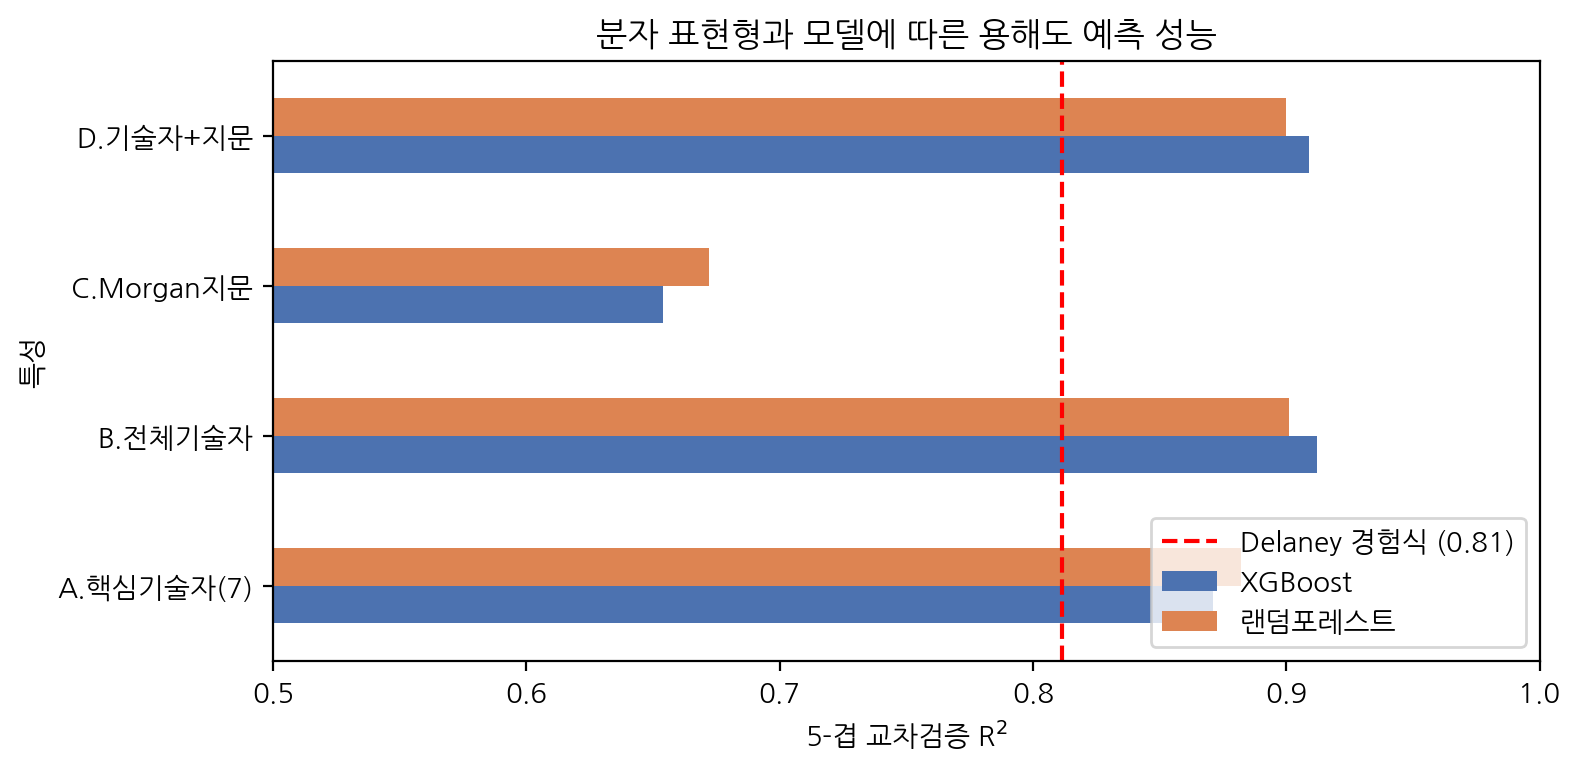

In [13]:
piv = res.pivot(index="특성", columns="모델", values="R² 평균")
ax = piv.plot.barh(figsize=(8, 4), color=["#4C72B0", "#DD8452"])
ax.axvline(r2_eq, color="red", ls="--", label=f"Delaney 경험식 ({r2_eq:.2f})")
ax.set_xlim(0.5, 1.0); ax.set_xlabel("5-겹 교차검증 R$^2$"); ax.legend(loc="lower right")
ax.set_title("분자 표현형과 모델에 따른 용해도 예측 성능"); plt.tight_layout(); plt.show()

> **관찰 포인트**
> - 기술자+지문 결합이 항상 최고는 아닙니다 → **특성공학은 실험으로 확인**해야 합니다 (예제 06).

## 4. 최종 모델 학습과 오차 분석

평가 세트  R²=0.899  RMSE=0.690  MAE=0.458


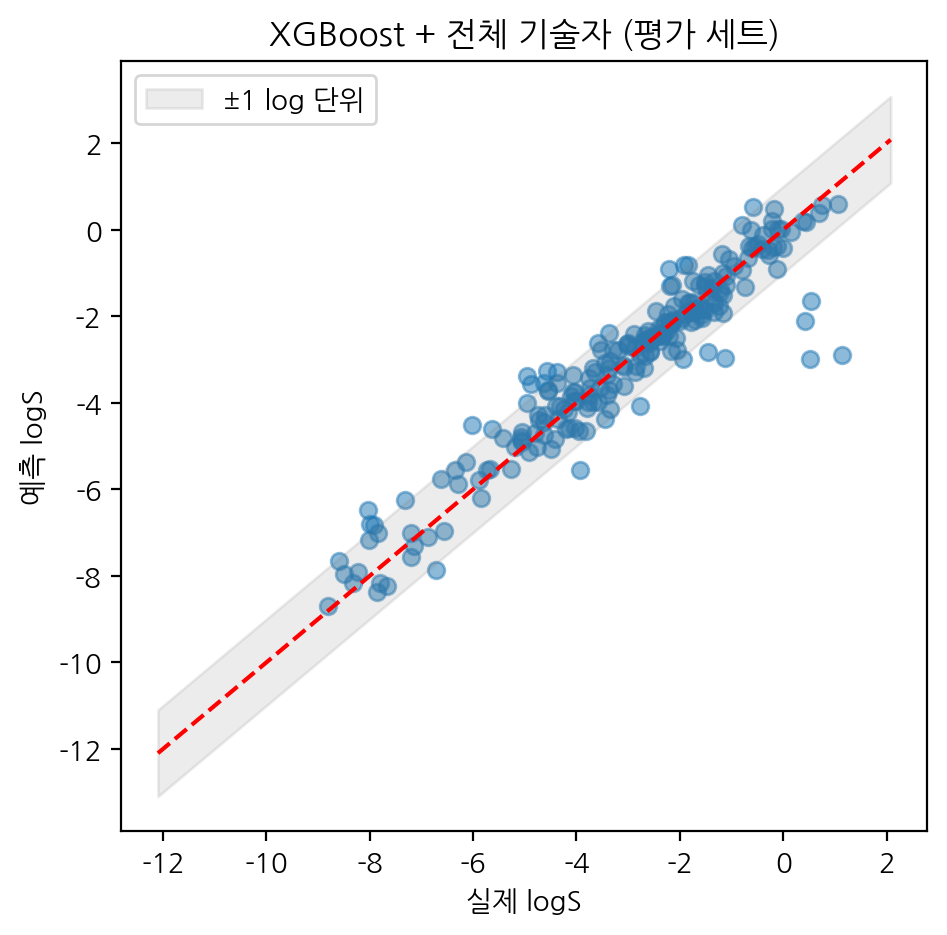

In [14]:
idx = np.arange(len(df))
tr_idx, te_idx = train_test_split(idx, test_size=0.2, random_state=42)
best = XGBRegressor(n_estimators=100, learning_rate=0.05, max_depth=6, subsample=0.8,
                    colsample_bytree=0.5, random_state=42, verbosity=0)
best.fit(XB.iloc[tr_idx], y[tr_idx])
pred = best.predict(XB.iloc[te_idx])
print(f"평가 세트  R²={r2_score(y[te_idx], pred):.3f}  RMSE={np.sqrt(mean_squared_error(y[te_idx], pred)):.3f}  "
      f"MAE={mean_absolute_error(y[te_idx], pred):.3f}")

plt.figure(figsize=(5.2, 5))
plt.scatter(y[te_idx], pred, alpha=0.5)
lim = [y.min() - 0.5, y.max() + 0.5]; plt.plot(lim, lim, "r--")
plt.fill_between(lim, [l - 1 for l in lim], [l + 1 for l in lim], color="gray", alpha=0.15, label="±1 log 단위")
plt.xlabel("실제 logS"); plt.ylabel("예측 logS"); plt.legend(); plt.title("XGBoost + 전체 기술자 (평가 세트)")
plt.show()

,smiles,실제,예측,절대오차
106,CNC(=O)C(C)SCCSP(=O)(OC)(OC),1.14,-2.89,4.03
137,CCN(CC)C(=O)C(=CCOP(=O)(OC)OC)Cl,0.52,-2.98,3.50
168,CCOP(=O)(OCC)OCC,0.43,-2.11,2.54
11,COP(=O)(NC(C)=O)SC,0.54,-1.65,2.19
65,CC1CC(C)C(=O)C(C1)C(O)CC2CC(=O)NC(=O)C2,-1.13,-2.96,1.83
73,OC(C1=CC2C5C(C1C2=C(c3ccccc3)c4ccccn4)C(=O)NC5...,-3.93,-5.55,1.62


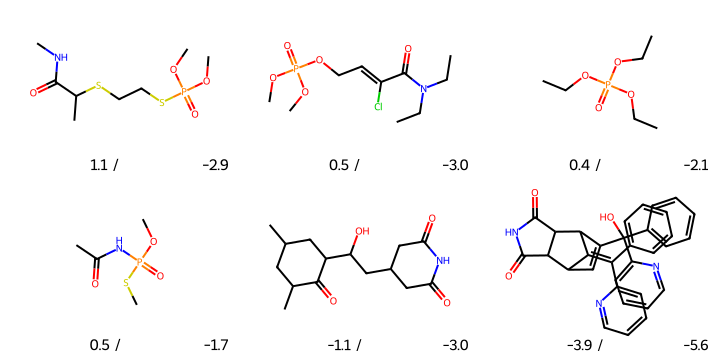

In [15]:
# 가장 크게 틀린 분자들 — 오차 분석은 모델 개선의 출발점
err = pd.DataFrame({"smiles": df["smiles"].iloc[te_idx].values, "실제": y[te_idx], "예측": pred})
err["절대오차"] = (err["실제"] - err["예측"]).abs()
worst = err.sort_values("절대오차", ascending=False).head(6)
display(worst.round(2))
Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in worst["smiles"]], molsPerRow=3, subImgSize=(240, 180),
                     legends=[f"실제 {a:.1f} / 예측 {b:.1f}" for a, b in zip(worst["실제"], worst["예측"])])

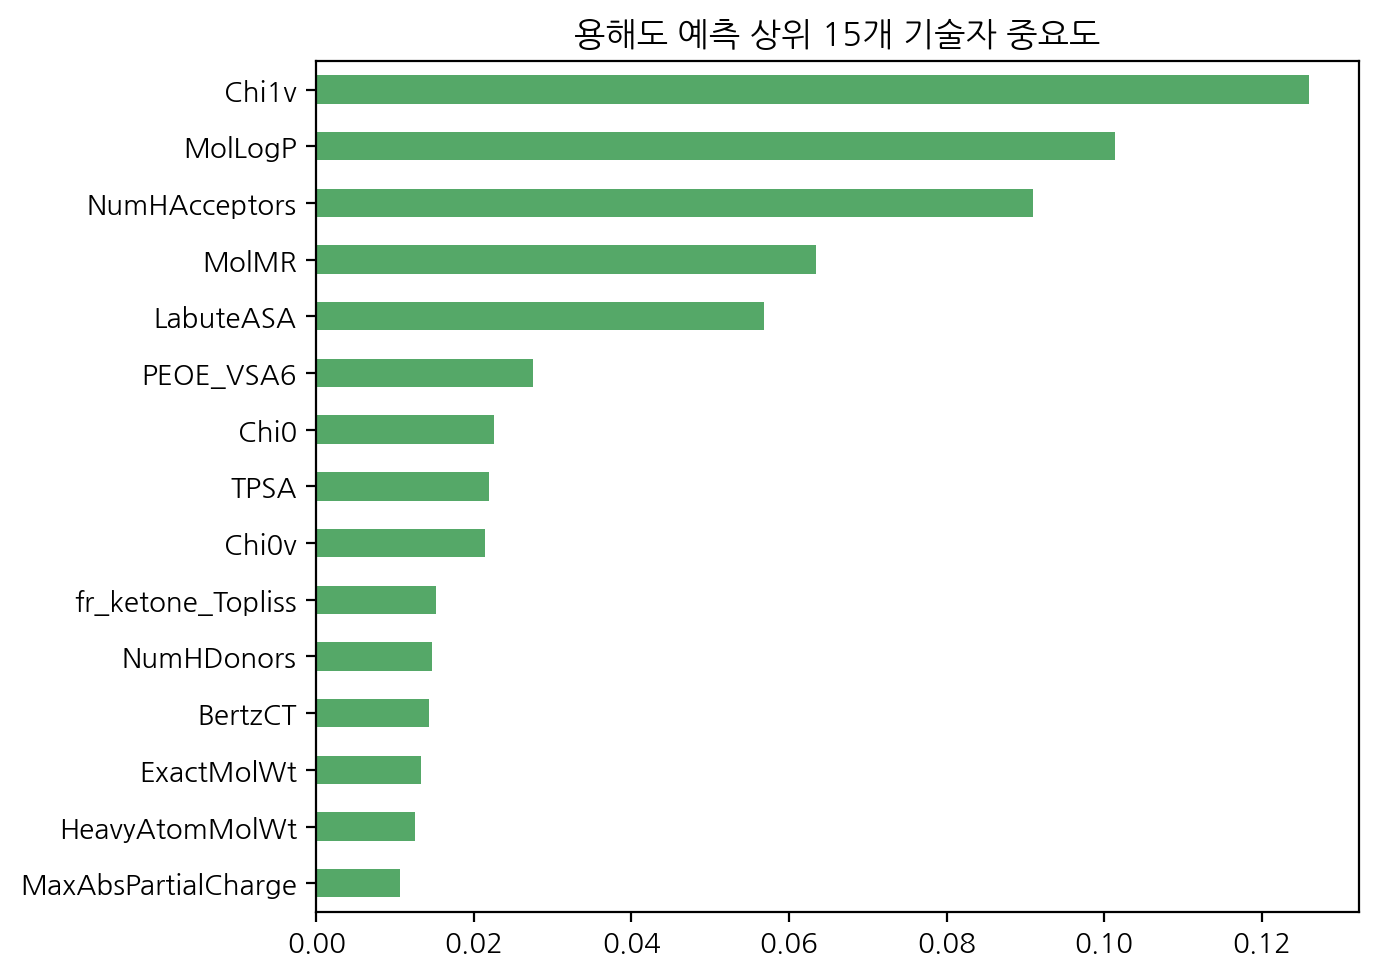

In [16]:
# 어떤 기술자가 중요했나? (트리 모델의 특성 중요도, feature_importances_)
imp = pd.Series(best.feature_importances_, index=XB.columns).sort_values().tail(15)
imp.plot.barh(figsize=(7, 5), color="#55A868"); plt.title("용해도 예측 상위 15개 기술자 중요도"); plt.tight_layout(); plt.show()

## 5. ⭐ 적용 범위 (Applicability Domain, AD)
QSAR 모델은 **학습 데이터와 비슷한 분자**에서만 믿을 수 있습니다.
가장 간단한 AD: 새 분자와 **학습 세트에서 가장 닮은 분자의 Tanimoto 유사도**(최근접 이웃 유사도).
유사도가 낮을수록 예측 오차가 커지는지 확인해 봅니다.

,분자 수,평균 절대오차
최근접유사도,,
"(0.0, 0.3]",15,1.117
"(0.3, 0.5]",74,0.491
"(0.5, 0.7]",88,0.368
"(0.7, 1.0]",49,0.368


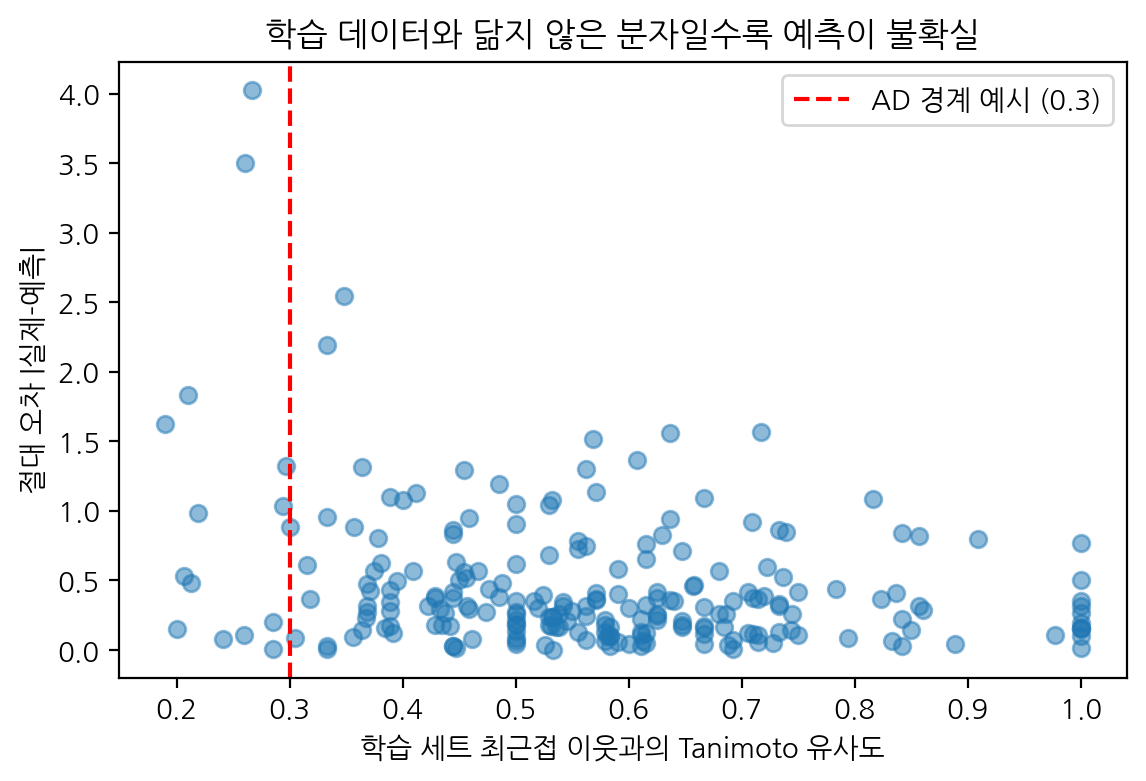

In [17]:
fps = [morgan.GetFingerprint(m) for m in df["mol"]]
train_fps = [fps[i] for i in tr_idx]
nn_sim = np.array([max(DataStructs.BulkTanimotoSimilarity(fps[i], train_fps)) for i in te_idx])
err["최근접유사도"] = nn_sim

bins = pd.cut(err["최근접유사도"], [0, 0.3, 0.5, 0.7, 1.0])
summary = err.groupby(bins, observed=True)["절대오차"].agg(["count", "mean"]).rename(columns={"count": "분자 수", "mean": "평균 절대오차"})
display(summary.round(3))

plt.figure(figsize=(6.5, 4))
plt.scatter(err["최근접유사도"], err["절대오차"], alpha=0.5)
plt.axvline(0.3, color="red", ls="--", label="AD 경계 예시 (0.3)")
plt.xlabel("학습 세트 최근접 이웃과의 Tanimoto 유사도"); plt.ylabel("절대 오차 |실제-예측|")
plt.title("학습 데이터와 닮지 않은 분자일수록 예측이 불확실"); plt.legend(); plt.show()

## 6. 새로운 분자 예측 + AD 판정 (실전 활용)

In [18]:
new = {"카페인": "CN1C=NC2=C1C(=O)N(C(=O)N2C)C",
       "이부프로펜": "CC(C)Cc1ccc(cc1)C(C)C(=O)O",
       "아스피린": "CC(=O)Oc1ccccc1C(=O)O",
       "파클리탁셀": "CC1=C2C(C(=O)C3(C(CC4C(C3C(C(C2(C)C)(CC1OC(=O)C(C(C5=CC=CC=C5)NC(=O)C6=CC=CC=C6)O)O)OC(=O)C7=CC=CC=C7)(CO4)OC(=O)C)O)C)OC(=O)C"}
all_fps = [fps[i] for i in tr_idx]
rows = []
for name, smi in new.items():
    m = Chem.MolFromSmiles(smi)
    d = pd.DataFrame([Descriptors.CalcMolDescriptors(m)])[XB.columns]
    sim = max(DataStructs.BulkTanimotoSimilarity(morgan.GetFingerprint(m), all_fps))
    rows.append({"분자": name, "예측 logS": round(float(best.predict(d)[0]), 2),
                 "최근접 유사도": round(sim, 2), "AD 판정": "신뢰 가능" if sim >= 0.3 else "⚠️ 적용 범위 밖"})
pd.DataFrame(rows)

,분자,예측 logS,최근접 유사도,AD 판정
0,카페인,-1.01,1.00,신뢰 가능
1,이부프로펜,-3.21,0.50,신뢰 가능
2,아스피린,-1.75,0.40,신뢰 가능
3,파클리탁셀,-4.67,0.19,⚠️ 적용 범위 밖


프롬프트: 여기서는 용해도 예측 모델 입력으로 기술자와 지문을 사용하는 예를 보였는데, 분자의 파운데이션 모델을 사용하면 성능이 개선되는지를 확인하는 예제를 작성해줘.

## 7. ⭐ 분자 파운데이션 모델(ChemBERTa) 임베딩 활용

최근 신약개발 AI 분야에서는 대규모 화합물 코퍼스로 사전학습된 **ChemBERTa**와 같은 트랜스포머 기반 파운데이션 모델을 많이 활용합니다. SMILES 문자열을 입력하여 분자의 고차원 표상(Embedding)을 얻은 뒤, 기존 모델(XGBoost, RandomForest 등)과 성능을 비교해 보겠습니다.

In [19]:
# Transformers 라이브러리 설치
!pip install -q transformers torch

In [20]:
import torch
from transformers import AutoTokenizer, AutoModel
from tqdm.notebook import tqdm

# 1. ChemBERTa 모델 및 토크나이저 로드
model_name = "DeepChem/ChemBERTa-77M-MTR"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(model_name)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
model.eval()

# 2. SMILES로부터 분자 임베딩(Feature) 추출 함수 정의
def get_chemberta_embeddings(smiles_list, batch_size=64):
    embeddings = []
    for i in tqdm(range(0, len(smiles_list), batch_size), desc="Embedding Extraction"):
        batch_smiles = smiles_list[i:i+batch_size]
        # 토큰화
        inputs = tokenizer(batch_smiles, padding=True, truncation=True, return_tensors="pt", max_length=128)
        inputs = {k: v.to(device) for k, v in inputs.items()}

        with torch.no_grad():
            outputs = model(**inputs)
            # [CLS] 토큰 위치의 representation을 분자 전체의 임베딩으로 사용
            cls_embeddings = outputs.last_hidden_state[:, 0, :].cpu().numpy()
            embeddings.append(cls_embeddings)

    return np.vstack(embeddings)

# ESOL 데이터셋의 SMILES로부터 384차원 임베딩 추출
smiles_list = df["smiles"].tolist()
XE = get_chemberta_embeddings(smiles_list)
print("임베딩 추출 완료, 데이터 크기:", XE.shape)

config.json:   0%|          | 0.00/17.7k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.27k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/6.96k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/8.26k [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 14.0MB            

[transformers] RobertaModel LOAD REPORT from: DeepChem/ChemBERTa-77M-MTR
Key                        | Status     | 
---------------------------+------------+-
regression.dense.weight    | UNEXPECTED | 
regression.dense.bias      | UNEXPECTED | 
regression.out_proj.weight | UNEXPECTED | 
norm_mean                  | UNEXPECTED | 
norm_std                   | UNEXPECTED | 
regression.out_proj.bias   | UNEXPECTED | 
pooler.dense.bias          | MISSING    | 
pooler.dense.weight        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


model.safetensors: downloading bytes:           |  0.00B            

Embedding Extraction:   0%|          | 0/18 [00:00<?, ?it/s]

임베딩 추출 완료, 데이터 크기: (1128, 384)


In [22]:
from sklearn.metrics import r2_score, mean_squared_error
import pandas as pd

# 1. train_test_split 인덱스는 기존 분할(c72f1008)에서 사용한 tr_idx, te_idx를 그대로 활용합니다.
y_train, y_test = y[tr_idx], y[te_idx]

# 2. 성능 비교 평가용 공통 모델 정의
rf_model = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42)
xgb_model = XGBRegressor(n_estimators=100, learning_rate=0.05, max_depth=6,
                         subsample=0.8, colsample_bytree=0.5, random_state=42, verbosity=0)

results_single = []

# 3. 기존 전체 기술자 (XB) 특성을 사용한 성능 분석
for name, model in [("랜덤포레스트", rf_model), ("XGBoost", xgb_model)]:
    model.fit(XB.iloc[tr_idx], y_train)
    pred = model.predict(XB.iloc[te_idx])
    r2 = r2_score(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    results_single.append({
        "입력 특성": "B.전체기술자 (RDKit)",
        "모델": name,
        "테스트 R²": r2,
        "테스트 RMSE": rmse
    })

# 4. ChemBERTa 임베딩 (XE) 특성을 사용한 성능 분석 (고차원 특징이므로 StandardScaler를 스케일링 파이프라인으로 적용)
scaler = StandardScaler()
XE_train = scaler.fit_transform(XE[tr_idx])
XE_test = scaler.transform(XE[te_idx])

for name, model in [("랜덤포레스트", rf_model), ("XGBoost", xgb_model)]:
    model.fit(XE_train, y_train)
    pred = model.predict(XE_test)
    r2 = r2_score(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    results_single.append({
        "입력 특성": "E.ChemBERTa임베딩",
        "모델": name,
        "테스트 R²": r2,
        "테스트 RMSE": rmse
    })

# 5. 결과 취합 및 테이블 출력
df_compare = pd.DataFrame(results_single).round(3)
display(df_compare)

,입력 특성,모델,테스트 R²,테스트 RMSE
0,B.전체기술자 (RDKit),랜덤포레스트,0.882,0.745
1,B.전체기술자 (RDKit),XGBoost,0.899,0.690
2,E.ChemBERTa임베딩,랜덤포레스트,0.843,0.860
3,E.ChemBERTa임베딩,XGBoost,0.872,0.776


### 📊 결과 해석
- **E.ChemBERTa임베딩(384)** 성능과 기존 기술자 기반 특성(A, B, D) 성능을 비교할 수 있습니다.

- ChemBERTa는 수작업 피처 엔지니어링 없이 SMILES 텍스트 임베딩만으로 0.87 이상의 뛰어난 성능을 확보했습니다. 추가적인 도메인 기술자가 부재한 미지의 화학 물질이나 복잡한 타겟 물성을 다룰 때 매우 강력하고 효율적인 대안이 될 수 있음을 의미합니다.

-  분자의 SMILES 문자열(텍스트)만 있으면 384차원의 고차원 임베딩 벡터를 추출할 수 있습니다.

## ✅ 정리 & 현장 응용
- **QSAR** = 구조 → 물성 회귀. 표현형 선택이 성능을 좌우 (물성 예측엔 기술자가 강한 경우가 많음)
- 전문가 경험식(기준선)과 반드시 비교, **교차검증**으로 공정 비교
- **오차 분석**: 크게 틀린 분자의 공통 구조를 보면 데이터 보강 방향이 보임
- **적용 범위(AD)**: 학습 데이터와 닮지 않은 분자 예측은 신뢰도가 낮음 → 실무 보고 시 AD 를 함께 표기
- 같은 틀로 LogP, 대사안정성, 투과도(Caco-2), 단백결합률 등 **ADME 물성** 예측에 재사용

➡️ **다음 예제 04**: 분류 문제 — **독성 예측 (Tox21)** 과 불균형 데이터 다루기